In [100]:
import pandas as pd
import numpy as np
import seaborn as sns

# Lichess analysis

In this notebook, we explore a dataset of chess games played on the online website lichess.org. This data set was found on Kaggle.com and the link to find the original dataset can be found [here](https://www.kaggle.com/datasets/datasnaek/chess).




## Fetching Data
The first thing to do is get the data so we can explore it locally. To do so we use the cell magic %%bash to run shell commands and use curl and unzip in order to fetch and unzip the data.

In [8]:
%%bash

#!/bin/bash
curl -L -o chess.zip https://www.kaggle.com/api/v1/datasets/download/datasnaek/chess && unzip -o chess.zip && rm chess.zip


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 2835k  100 2835k    0     0  2603k      0  0:00:01  0:00:01 --:--:-- 3726k


Archive:  chess.zip
  inflating: games.csv               


## Initial Exploration
Now that we have the data in our current directory, we will use pandas in order to load it into memory and start exploring. 

In [101]:
df = pd.read_csv("games.csv")

In [102]:
print("Shape: " + str(df.shape)) # see how many records
print("Features: " + str(df.columns)) # see whats in each record
print(df.head()) #see first 5 records 


Shape: (20058, 16)
Features: Index(['id', 'rated', 'created_at', 'last_move_at', 'turns', 'victory_status',
       'winner', 'increment_code', 'white_id', 'white_rating', 'black_id',
       'black_rating', 'moves', 'opening_eco', 'opening_name', 'opening_ply'],
      dtype='object')
         id  rated    created_at  last_move_at  turns victory_status winner  \
0  TZJHLljE  False  1.504210e+12  1.504210e+12     13      outoftime  white   
1  l1NXvwaE   True  1.504130e+12  1.504130e+12     16         resign  black   
2  mIICvQHh   True  1.504130e+12  1.504130e+12     61           mate  white   
3  kWKvrqYL   True  1.504110e+12  1.504110e+12     61           mate  white   
4  9tXo1AUZ   True  1.504030e+12  1.504030e+12     95           mate  white   

  increment_code       white_id  white_rating      black_id  black_rating  \
0           15+2       bourgris          1500          a-00          1191   
1           5+10           a-00          1322     skinnerua          1261   
2         

Now the first thing that pops out to me and something which I would want analyze is the rating. I think that most people seeing this data set would initally ask questions such as "What are higher rated players doing that I am not?" or "What opening is used by the best players?" etc etc. 

Lets first see what a "higher" rater player even means:

In [103]:
print(df["white_rating"].describe())
print(df["black_rating"].describe())

count    20058.000000
mean      1596.631868
std        291.253376
min        784.000000
25%       1398.000000
50%       1567.000000
75%       1793.000000
max       2700.000000
Name: white_rating, dtype: float64
count    20058.000000
mean      1588.831987
std        291.036126
min        789.000000
25%       1391.000000
50%       1562.000000
75%       1784.000000
max       2723.000000
Name: black_rating, dtype: float64


We will estimate that an amatuer game consists of someone more than one standard deviation away from the 75% interquartile range. So next, lets find all *rated* games which fall into that category of one player being 2100 or higher. 

And for comparison lets find the reverse of that.

In [104]:
amatuers = df[(df["white_rating"] >= 2100) | (df["black_rating"] >= 2100)]
amatuers = amatuers[amatuers["rated"] == True]

In [105]:
beginners = df[(df["white_rating"] <= 1100) | (df["black_rating"] <= 1100)]
beginners = beginners[beginners["rated"] == True]

In [106]:
print(amatuers.shape)
print(beginners.shape)

(1271, 16)
(921, 16)


In [107]:
df.groupby("opening_name").size().sort_values(ascending=False).head(10)

opening_name
Van't Kruijs Opening                             368
Sicilian Defense                                 358
Sicilian Defense: Bowdler Attack                 296
Scotch Game                                      271
French Defense: Knight Variation                 271
Scandinavian Defense: Mieses-Kotroc Variation    259
Queen's Pawn Game: Mason Attack                  232
Queen's Pawn Game: Chigorin Variation            229
Scandinavian Defense                             223
Horwitz Defense                                  209
dtype: int64

In [108]:
amatuers.groupby("opening_name").size().sort_values(ascending=False).head(10)

opening_name
Indian Game                           19
Sicilian Defense                      16
Queen's Pawn Game: London System      14
Horwitz Defense                       14
Queen's Pawn Game: Mason Attack       13
French Defense: Exchange Variation    10
Modern Defense                        10
French Defense: Knight Variation      10
Queen's Gambit Declined               10
Ruy Lopez: Berlin Defense #2           9
dtype: int64

In [109]:
beginners.groupby("opening_name").size().sort_values(ascending=False).head(10)

opening_name
Van't Kruijs Opening                             53
Scandinavian Defense                             40
Sicilian Defense                                 19
Queen's Pawn Game                                19
Queen's Pawn Game: Chigorin Variation            18
King's Pawn Game: Wayward Queen Attack           18
King's Pawn Game: Leonardis Variation            16
Scandinavian Defense: Mieses-Kotroc Variation    15
Hungarian Opening                                15
French Defense: Knight Variation                 15
dtype: int64

## CHART 1: Slope Graph of what openings players use based on rating

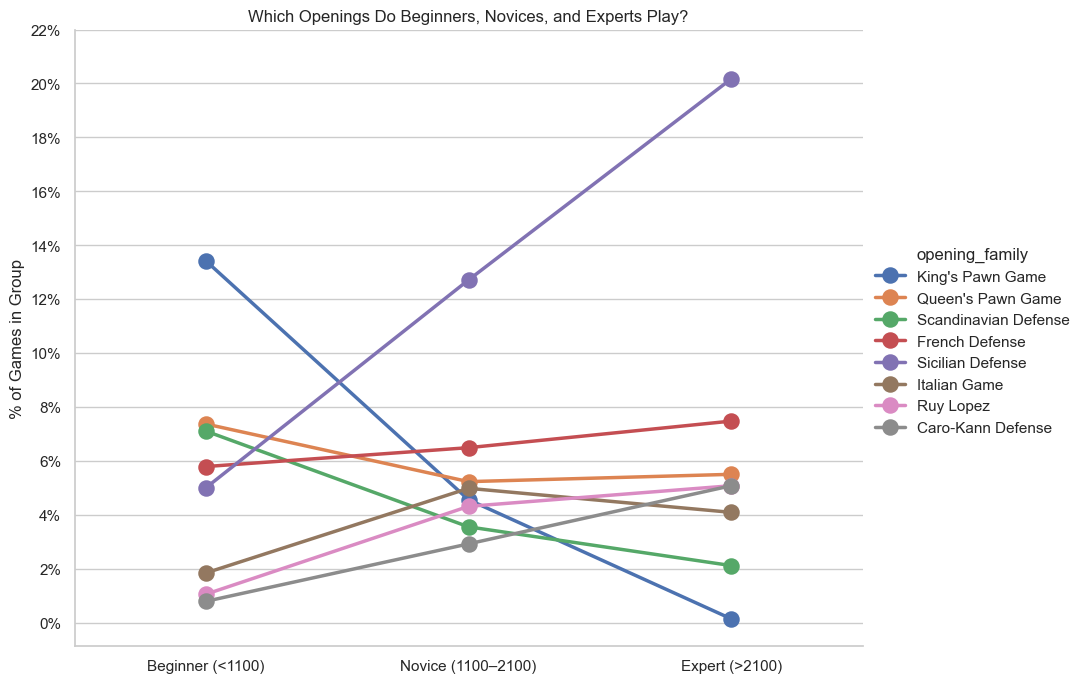

In [81]:
df["avg_rating"] = (df["white_rating"] + df["black_rating"]) / 2
df["group"] = "Novice (1100–2100)"
df.loc[df["avg_rating"] < 1100, "group"] = "Beginner (<1100)"
df.loc[df["avg_rating"] > 2100, "group"] = "Expert (>2100)"

group_order = ["Beginner (<1100)", "Novice (1100–2100)", "Expert (>2100)"]

# Collapse variations: "Sicilian Defense: Najdorf" -> "Sicilian Defense"
df["opening_family"] = df["opening_name"].str.split(":").str[0].str.split("|").str[0].str.strip()

share = (df.groupby("group")["opening_family"].value_counts(normalize=True)
           .rename("pct").reset_index())

# Keep openings that are top 5 in any group
top = share.groupby("group").head(5)["opening_family"].unique()
share = share[share["opening_family"].isin(top)]

sns.set_theme(style="whitegrid")
g = sns.catplot(data=share, x="group", y="pct", hue="opening_family",
                kind="point", order=group_order,
                height=7, aspect=1.3, markersize=10, linewidth=2.5)
g.set_axis_labels("", "% of Games in Group")
g.set(title="Which Openings Do Beginners, Novices, and Experts Play?")
ticks = [i / 100 for i in range(0, int(share["pct"].max() * 100) + 3, 2)]
g.set(yticks=ticks, yticklabels=[f"{int(t*100)}%" for t in ticks])

## Chart 2: Seeing the number of times black vs white wins with the sicilian defense.

Histogram where each bin is 100 rating and then each box is black white or gray for ties

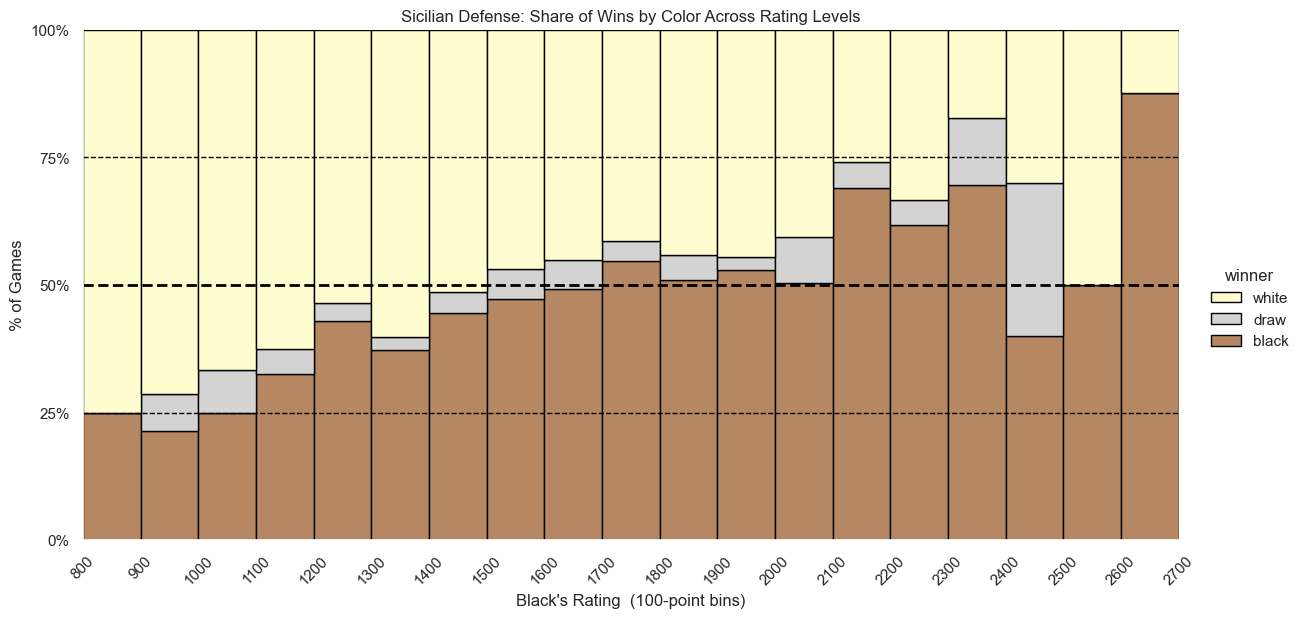

In [70]:
sicilian = df[df["opening_name"].str.contains("Sicilian Defense", na=False)].copy()


# Line the bins up on round hundreds (1200, 1300, ...)
lo = int(sicilian["black_rating"].min() // 100 * 100 + 100) 
hi = int(sicilian["black_rating"].max() // 100 * 100 + 100)

sns.set_theme(style="darkgrid")

g = sns.displot(
    data=sicilian,
    x="black_rating",
    hue="winner",
    hue_order=["white", "draw", "black"],
    palette={"white": "#FFFDD0", "black": "#B58863", "draw": "#D3D3D3"},
    kind="hist",
    binwidth=100,
    binrange=(lo, hi),
    multiple="fill",       # each bin sums to 100%
    edgecolor="black",
    alpha=1,
    height=6,
    aspect=2,
)


g.refline(y=.5, color="black", linestyle="--", linewidth=2)

for y in [0.25, 0.75]:
    g.refline(y=y, color="black", linestyle="--", linewidth=1)

g.set_axis_labels("Black's Rating  (100-point bins)", "% of Games")
g.set(
    title="Sicilian Defense: Share of Wins by Color Across Rating Levels",
    xticks=range(lo, hi + 1, 100),
    yticks=[0, 0.25, 0.5, 0.75, 1],
    yticklabels=["0%", "25%", "50%", "75%", "100%"],
)
g.tick_params(axis="x", rotation=45)

## Chart 3: Do stronger players Follow Opening Theory Longer?

Confidence interval chart which shows how many moves of opening theory each rating uses on average 

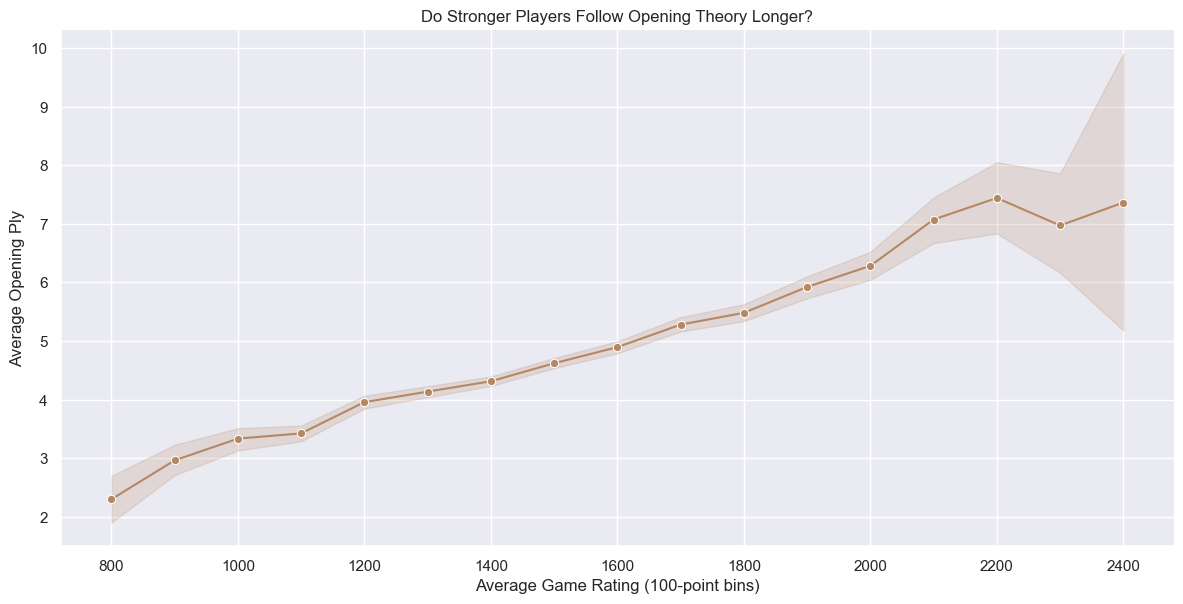

In [71]:
df["avg_rating"] = (df["white_rating"] + df["black_rating"]) / 2
df["rating_bin"] = (df["avg_rating"] // 100 * 100).astype(int)

sns.set_theme(style="darkgrid")

g = sns.relplot(
    data=df,
    x="rating_bin",
    y="opening_ply",
    kind="line",
    marker="o",
    color="#B58863",
    height=6,
    aspect=2,
)
g.set_axis_labels("Average Game Rating (100-point bins)", "Average Opening Ply")
g.set(title="Do Stronger Players Follow Opening Theory Longer?")

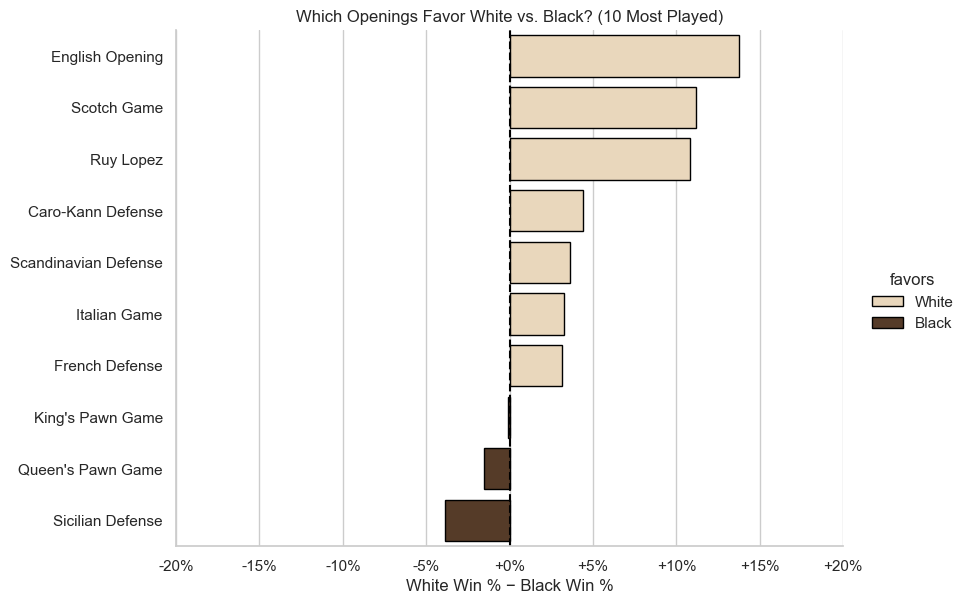

In [112]:
import pandas as pd
import seaborn as sns

df = pd.read_csv("games.csv")
df["opening_family"] = df["opening_name"].str.split(":").str[0].str.split("|").str[0].str.strip()

# 10 most-played opening families
top10 = df["opening_family"].value_counts().head(10).index
sub = df[df["opening_family"].isin(top10)]

edge = (sub.groupby("opening_family")["winner"]
          .value_counts(normalize=True).unstack(fill_value=0))
edge["advantage"] = edge["white"] - edge["black"]
edge = edge.sort_values("advantage", ascending=False).reset_index()
edge["favors"] = edge["advantage"].apply(lambda x: "White" if x > 0 else "Black")

sns.set_theme(style="whitegrid")
g = sns.catplot(
    data=edge,
    x="advantage",
    y="opening_family",
    hue="favors",
    kind="bar",
    order=edge["opening_family"],
    palette={"White": "#F0D9B5", "Black": "#5C3A21"},
    edgecolor="black",
    dodge=False,
    height=6,
    aspect=1.5,
)
g.refline(x=0, color="black", linewidth=1.5)
g.set_axis_labels("White Win % − Black Win %", "")
g.set(title="Which Openings Favor White vs. Black? (10 Most Played)")

lim = round(edge["advantage"].abs().max() + 0.05, 1)
ticks = [i / 100 for i in range(int(-lim * 100), int(lim * 100) + 1, 5)]
g.set(xticks=ticks, xticklabels=[f"{int(t*100):+d}%" for t in ticks])

[Text(0.5, 1.0, 'Which Side Does Each Opening Favor at Each Skill Level?'),
 Text(0.5, 33.249999999999986, 'Average Game Rating'),
 Text(117.24999999999997, 0.5, '')]

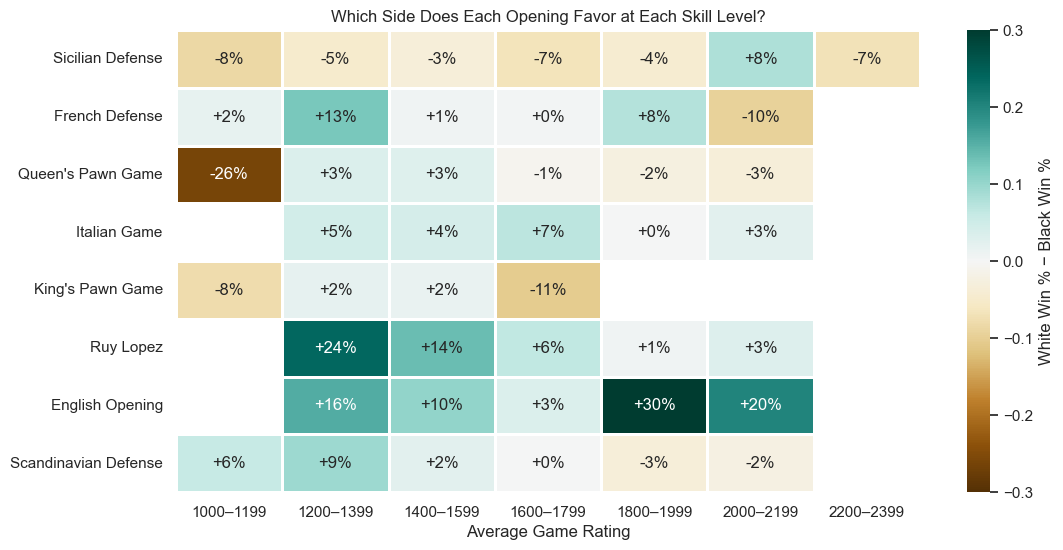

In [113]:

df = pd.read_csv("games.csv")
df["opening_family"] = df["opening_name"].str.split(":").str[0].str.split("|").str[0].str.strip()
df["avg_rating"] = (df["white_rating"] + df["black_rating"]) / 2

# 200-point rating bands (100 would leave too many empty cells)
df["band"] = (df["avg_rating"] // 200 * 200).astype(int)
df = df[df["band"].between(1000, 2200)]

top8 = df["opening_family"].value_counts().head(8).index
sub = df[df["opening_family"].isin(top8)].copy()

sub["white_win"] = (sub["winner"] == "white").astype(int)
sub["black_win"] = (sub["winner"] == "black").astype(int)

stats = sub.groupby(["opening_family", "band"]).agg(
    games=("id", "count"),
    white=("white_win", "mean"),
    black=("black_win", "mean"),
)
stats["advantage"] = stats["white"] - stats["black"]

grid = stats["advantage"].unstack()
counts = stats["games"].unstack()
grid = grid.loc[top8]                      # rows ordered by popularity
grid.columns = [f"{c}–{c+199}" for c in grid.columns]

sns.set_theme(style="white", rc={"figure.figsize": (12, 6)})
ax = sns.heatmap(
    grid,
    mask=counts.loc[top8].values < 30,     # hide cells with too few games
    cmap="BrBG",
    center=0,
    vmin=-0.3, vmax=0.3,
    annot=True, fmt="+.0%",
    linewidths=1, linecolor="white",
    cbar_kws={"label": "White Win % − Black Win %"},
)
ax.set(title="Which Side Does Each Opening Favor at Each Skill Level?",
       xlabel="Average Game Rating", ylabel="")